# Process data: LabVIEW and the lab-control software

`ProcessData` holds the operational data of a set-up, whatever ran it: the
LabVIEW log of Box 5 and the day files of `box2-control` and `box5-control`.
One layout: `pv`, `sp`, `status`, ... over `tos` x `channel`, the channel's
unit, quantity and species as coordinates, plus sessions, events and valve
switches. The day files read here are the fixtures under
`tests/processdata/` (excerpts of real Box 2 days; a Box 5 day written by
box5-control's own writer).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import lab_data_parser as ldp
from lab_data_parser.processdata import BOX5_CONTROL_TAGS

FIXTURES = Path("..") / "tests" / "processdata"

## Box 2: a day file and its events

`from_day_log` takes a file, a list or the data folder; the event log is
found in the `logs` folder beside it. The session that ran over midnight
spans both day files and keeps one number and one origin.

In [2]:
box2 = ldp.ProcessData.from_day_log(FIXTURES / "box2" / "data")
print(box2)
box2.sessions[0]["files"], box2.tos_start

ProcessData(set_up='box2', n_samples=240, channels=6, fields=['pv', 'status', 'sp'], sessions=1, events=12, duration=243.2s, tos_start=2026-10-21 22:56:24.605407+02:00)


(['2026-10-21_box2.csv', '2026-10-22_box2.csv'],
 Timestamp('2026-10-21 22:56:24.605407+0200', tz='Europe/Amsterdam'))

In [3]:
box2.ds[["quantity", "unit", "kind", "device", "device_unit", "description"]].to_dataframe()

,quantity,unit,kind,device,device_unit,description,species,writable
channel,,,,,,,,
PI-200,pressure,bar(a),indicator,omega,bar(g),booster inlet,,False
PI-201,pressure,bar(a),indicator,omega,bar(g),booster outlet,,False
PI-202,pressure,bar(a),indicator,omega,bar(g),H2 storage,,False
PI-900,pressure,bar(a),indicator,omega,bar(g),reactor inlet,,False
PI-901,pressure,bar(a),indicator,omega,bar(g),reactor outlet,,False
TIC-001,temperature,degC,indicator+controller,demo_heater,degC,demo heater zone,,True


In [4]:
# a value is NaN exactly where its status says the reading failed
pv, status = box2.get_channel("PI-202"), box2.get_channel("PI-202", "status")
print(np.isnan(pv).sum(), (status == 2).sum())
box2.events[["time", "tos", "level", "source", "text"]].head()

240 240


,time,tos,level,source,text
0,2026-10-21 23:06:25.070000+02:00,600.464593,INFO,devices.omega.device,"Omega on COM5, last 10 min: PI-200 (address 9)..."
1,2026-10-21 23:16:25.995000+02:00,1201.389593,INFO,devices.omega.device,"Omega on COM5, last 10 min: PI-200 (address 9)..."
2,2026-10-21 23:26:27.032000+02:00,1802.426593,INFO,devices.omega.device,"Omega on COM5, last 10 min: PI-200 (address 9)..."
3,2026-10-21 23:36:27.477000+02:00,2402.871593,INFO,devices.omega.device,"Omega on COM5, last 10 min: PI-200 (address 9)..."
4,2026-10-21 23:46:28.316000+02:00,3003.710593,INFO,devices.omega.device,"Omega on COM5, last 10 min: PI-200 (address 9)..."


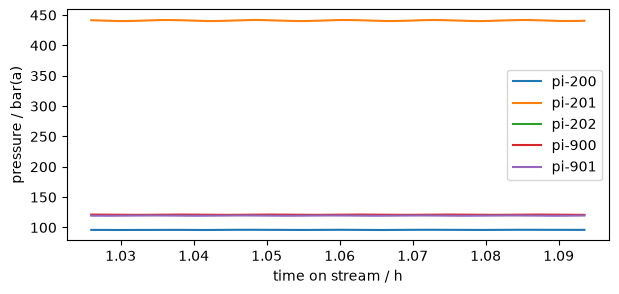

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
for tag in box2.channels_of("pressure"):
    ax.plot(box2.tos / 3600, box2.get_channel(tag), label=tag.lower())
ax.set_xlabel("time on stream / h")
ax.set_ylabel("pressure / bar(a)")
ax.legend()
plt.show()

## Box 2 with an MFC: setpoint layers, owner, mode, calibration

Written by box2-control's own `CsvWriter`: a controller carries its target,
the working setpoint of a ramp, the requested one, who owns it, and the MFC's
control mode. The NetCDF that `box2 export` writes reads the same.

In [6]:
controller = ldp.ProcessData.from_day_log(FIXTURES / "box2" / "controller" / "2026-10-23_box2.csv")
print(controller.fields)
pd.DataFrame({field: controller.get_channel("FIC-500", field) for field in ("pv", "target", "working", "owner", "mode")}).head(12)

['pv', 'status', 'sp', 'target', 'working', 'requested', 'owner', 'mode']


,pv,target,working,owner,mode
0,0.0,50.0,0.0,2,0
1,5.0,50.0,5.0,2,0
2,10.0,50.0,10.0,2,0
3,15.0,50.0,15.0,2,0
4,20.0,50.0,20.0,2,0
5,25.0,50.0,25.0,2,0
6,30.0,50.0,30.0,2,0
7,NaN,50.0,35.0,2,0
8,40.0,50.0,40.0,2,0
9,45.0,50.0,45.0,2,0


In [7]:
controller.calibrations

[{'tag': 'PI-900',
  'offset': 0.012,
  'previous': 0.0,
  'unit': 'bar(a)',
  'time': '2026-10-23T14:00:00+02:00',
  'raw_mean': 1.025,
  'noise': 0.001,
  'count': 10}]

## Box 5: corrected flows, valve switches

box5-control logs an MFC's PV times its correction factor (as LabVIEW did)
and its own figure as `device_pv`; the factor is a coordinate. Every valve
switch is a record with its own time, lined up on the same `tos`.

In [8]:
box5 = ldp.ProcessData.from_day_log(FIXTURES / "box5" / "data")
print(box5)
box5.ds[["species", "feed", "factor"]].to_dataframe().dropna()

ProcessData(set_up='box5', n_samples=190, channels=12, fields=['pv', 'sp', 'device_pv', 'device_sp', 'status'], sessions=3, events=8, switches=1, duration=54019.0s, tos_start=2026-10-23 09:00:00+02:00)

,species,feed,factor,quantity,unit,kind,device,description,corrected,factor_source,read_back
channel,,,,,,,,,,,
F1-1-He,He,1.0,1.123,flow,mLn/min,controller,FLOW-BUS COM44 node 6,"feed 1, He",True,"LabVIEW v02; sheet F-201CV M0203028B, 1.2.2026...",
F1-2-H2,H2,1.0,1.114,flow,mLn/min,controller,FLOW-BUS COM44 node 1,"feed 1, H2",True,"LabVIEW v02; sheet F-201CV M0203028A, 1.2.2026...",
F1-3-CO2,CO2,1.0,1.001,flow,mLn/min,controller,FLOW-BUS COM44 node 9,"feed 1, CO2",True,"LabVIEW v02; sheet F-201CV M11210304C, 1.2.202...",
F1-4-CO,CO,1.0,1.510,flow,mLn/min,controller,FLOW-BUS COM44 node 11,"feed 1, CO",True,LabVIEW v02; sheet F-201CV-RA-11-V 99203502H (...,
F2-1-He,He,2.0,1.084,flow,mLn/min,controller,FLOW-BUS COM44 node 3,"feed 2, He",True,LabVIEW v02; sheet F-201CV M11210304B: 1.0837,
F2-2-H2,H2,2.0,1.149,flow,mLn/min,controller,FLOW-BUS COM44 node 2,"feed 2, H2",True,LabVIEW v02 (saved as 'F2-1-H2 F'); sheet F-20...,
F2-3-CO2,CO2,2.0,1.383,flow,mLn/min,controller,FLOW-BUS COM44 node 4,"feed 2, CO2",True,LabVIEW v02; sheet F-201CV M20203028C: 1.3826,
F2-5-Ar,Ar,2.0,1.149,flow,mLn/min,controller,FLOW-BUS COM44 node 5,"feed 2, Ar",True,LabVIEW v02; sheet FG-201CV M25204466B: 1.1486,


In [9]:
box5.switches

,time,tos,kind,feed_before,feed_after,sent,confirmed,step,cycle,note
0,2026-10-23 09:01:00+02:00,60.0,observed,1.0,2.0,NaT,2026-10-23 09:01:00+02:00,NaN,NaN,seen by read-back


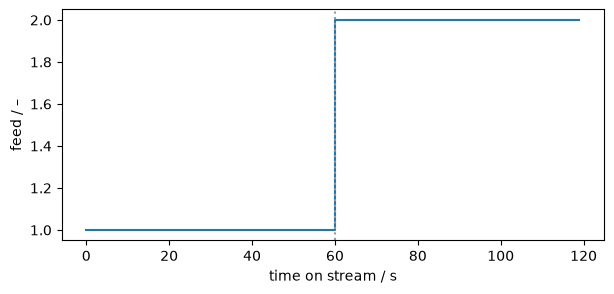

In [10]:
first = box5.select_session(1)
fig, ax = plt.subplots(figsize=(7, 3))
ax.step(first.tos, first.get_channel("Valve"), where="post")
for tos in first.switches["tos"]:
    ax.axvline(tos, color="0.6", linestyle=":")
ax.set_xlabel("time on stream / s")
ax.set_ylabel("feed / –")
plt.show()

## LabVIEW (Box 5) on box5-control's tags

The LabVIEW log has PV only. Each file is one session (one LabVIEW start).
`rename_channels(BOX5_CONTROL_TAGS)` puts it on the tags of box5-control, so
old and new runs are read by the same analysis code. LabVIEW v02 multiplied
the Ar reading by the He factor; `scale` corrects it.

In [11]:
tos_start = pd.Timestamp("2026-03-26 15:27:00", tz="Europe/Amsterdam")
labview = (
    ldp.ProcessData.from_labview_b67box5(Path("data") / "drifts_run" / "labview", tos_start=tos_start)
    .rename_channels(BOX5_CONTROL_TAGS)
    .scale("F2-5-Ar", 1.149 / 1.123)
)
print(labview)
labview.channels

ProcessData(set_up='box5', n_samples=4558, channels=11, fields=['pv', 'status'], sessions=3, duration=22794.0s, tos_start=2026-03-26 15:27:00+01:00)


['Cell T',
 'BPR Analytic',
 'BPR Vent',
 'F1-1-He',
 'F1-2-H2',
 'F1-3-CO2',
 'F2-1-He',
 'F2-2-H2',
 'F2-3-CO2',
 'F2-5-Ar',
 'Valve']

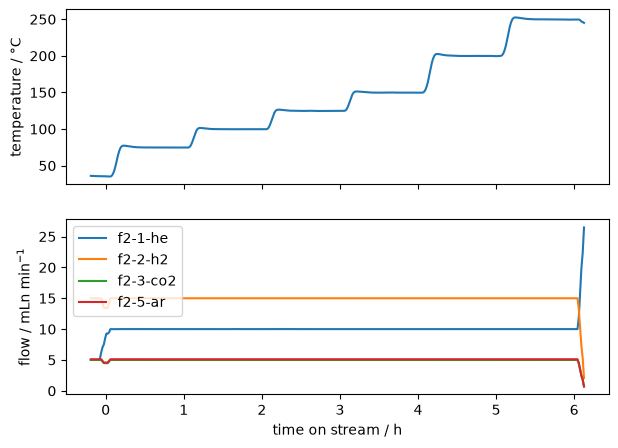

1. 2026-10-23T06:49:49+00:00  from_labview_b67box5(filepath='data\\drifts_run\\labview', tos_start='2026-03-26T15:27:00+01:00', keep_unknown_channels=false)
2. 2026-10-23T06:49:49+00:00  rename_channels(mapping={"Reactor T": "Cell T", "Analytic P": "BPR Analytic", "Vent P": "BPR Vent", "F1 He": "F1-1-He", "F1 H2": "F1-2-H2", "F1 CO2": "F1-3-CO2", "F1 CO": "F...)
3. 2026-10-23T06:49:49+00:00  scale(channel='F2-5-Ar', factor=1.0231522707034728, fields=["pv"])
4. 2026-10-23T06:49:49+00:00  resample(step_s=60, method='mean')
5. 2026-10-23T06:49:49+00:00  smooth_moving(window_size=5)


In [12]:
smooth = labview.resample(60).smooth_moving(5)
fig, (ax_t, ax_f) = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
ax_t.plot(smooth.tos / 3600, smooth.get_channel("Cell T"))
ax_t.set_ylabel("temperature / °C")
for tag in smooth.channels_of("flow", species=None):
    if smooth.ds["feed"].sel(channel=tag).item() == 2:
        ax_f.plot(smooth.tos / 3600, smooth.get_channel(tag), label=tag.lower())
ax_f.set_ylabel("flow / mLn min$^{-1}$")
ax_f.set_xlabel("time on stream / h")
ax_f.legend()
plt.show()
print(smooth.format_history())

## Species names and export

`rename_species` maps the `species` coordinate onto the naming convention;
the parsers never rename on read. `to_netcdf` keeps everything: values,
sessions, events, switches and the history.

In [13]:
box5.rename_species().ds["species"].values

array(['He', 'H2', 'CO2', 'CO', 'He', 'H2', 'CO2', 'Ar', '', '', '', ''],
      dtype=object)

In [14]:
box5.to_dataframe(with_timestamps=True).head()

,timestamp,F1-1-He,F1-2-H2,F1-3-CO2,F1-4-CO,F2-1-He,F2-2-H2,F2-3-CO2,F2-5-Ar,BPR Analytic,BPR Vent,Cell T,Valve
tos,,,,,,,,,,,,,
0.0,2026-10-23 09:00:00+02:00,22.46,2.228,2.002,3.02,21.68,2.298,2.766,2.298,1.3,1.3,150.0000,1.0
1.0,2026-10-23 09:00:01+02:00,22.46,2.228,2.002,3.02,21.68,2.298,2.766,2.298,1.3,1.3,150.0167,1.0
2.0,2026-10-23 09:00:02+02:00,22.46,2.228,2.002,3.02,21.68,2.298,2.766,2.298,1.3,1.3,150.0333,1.0
3.0,2026-10-23 09:00:03+02:00,22.46,2.228,2.002,3.02,21.68,2.298,2.766,2.298,1.3,1.3,150.0500,1.0
4.0,2026-10-23 09:00:04+02:00,22.46,2.228,2.002,3.02,21.68,2.298,2.766,2.298,1.3,1.3,150.0667,1.0
